In [1]:
#import the librairies

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Import the data

df = pd.read_csv("movies.csv")


In [2]:
## Display the first 5 rows of the dataframe

df.head()

,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime
0,The Shining,R,Drama,1980,"June 13, 1980 (United States)",8.4,927000.0,Stanley Kubrick,Stephen King,Jack Nicholson,United Kingdom,19000000.0,46998772.0,Warner Bros.,146.0
1,The Blue Lagoon,R,Adventure,1980,"July 2, 1980 (United States)",5.8,65000.0,Randal Kleiser,Henry De Vere Stacpoole,Brooke Shields,United States,4500000.0,58853106.0,Columbia Pictures,104.0
2,Star Wars: Episode V - The Empire Strikes Back,PG,Action,1980,"June 20, 1980 (United States)",8.7,1200000.0,Irvin Kershner,Leigh Brackett,Mark Hamill,United States,18000000.0,538375067.0,Lucasfilm,124.0
3,Airplane!,PG,Comedy,1980,"July 2, 1980 (United States)",7.7,221000.0,Jim Abrahams,Jim Abrahams,Robert Hays,United States,3500000.0,83453539.0,Paramount Pictures,88.0
4,Caddyshack,R,Comedy,1980,"July 25, 1980 (United States)",7.3,108000.0,Harold Ramis,Brian Doyle-Murray,Chevy Chase,United States,6000000.0,39846344.0,Orion Pictures,98.0


### 1. Data cleaning

In [3]:
# Check missing values
missing = df.isna().sum()

missing_pct = round( (missing / len(df)) * 100, 2)

missing_df = pd.DataFrame({
    'missing': missing,
    'missing_pct': missing_pct
})

missing_df = missing_df.sort_values('missing_pct', ascending=False)

missing_df

,missing,missing_pct
budget,2171,28.31
gross,189,2.46
rating,77,1.00
company,17,0.22
runtime,4,0.05
score,3,0.04
votes,3,0.04
country,3,0.04
writer,3,0.04
released,2,0.03


In [4]:
# Numerical columns
df['budget'] = df['budget'].fillna(df['budget'].median())
df['gross'] = df['gross'].fillna(df['gross'].median())

# Categorical columns
for col in ['company', 'country', 'writer', 'star']:
    df[col] = df[col].fillna('Unknown')

# Very few missing values
df = df.dropna(subset=['rating', 'runtime', 'score', 'votes'])

#checking the data

df.isna().sum()


name        0
rating      0
genre       0
year        0
released    0
score       0
votes       0
director    0
writer      0
star        0
country     0
budget      0
gross       0
company     0
runtime     0
dtype: int64

In [5]:
#inspecting the data types
df.dtypes

name         object
rating       object
genre        object
year          int64
released     object
score       float64
votes       float64
director     object
writer       object
star         object
country      object
budget      float64
gross       float64
company      object
runtime     float64
dtype: object

In [6]:
# chnaging the data types of columns

df['budget']= df['budget'].astype('int64')
df['gross']= df['gross'].astype('int64')


In [7]:
df= df.sort_values(by= ['gross'], inplace = False , ascending = False)

In [8]:
pd.set_option('display.max_rows', None)

In [9]:
# Check duplicate records
duplicate_count = df.duplicated().sum()
print(f"Duplicate rows found: {duplicate_count}")

# Remove duplicates
df.drop_duplicates(inplace=True)

print(f"Dataset shape after removing duplicates: {df.shape}")

Duplicate rows found: 0
Dataset shape after removing duplicates: (7587, 15)


### 2. Correlation

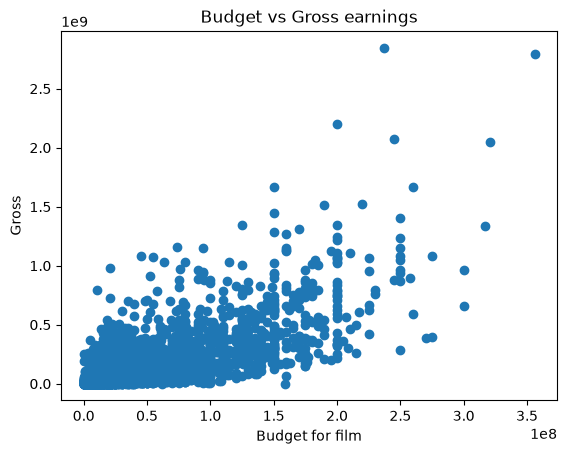

In [10]:
# Does the budget of a movie influence its gross earnings?
#  scatter plot with budget vs gross

plt.scatter(x=df['budget'], y=df['gross'])
plt.xlabel('Budget for film')
plt.ylabel('Gross')
plt.title('Budget vs Gross earnings')
plt.show()

<Axes: xlabel='budget', ylabel='gross'>

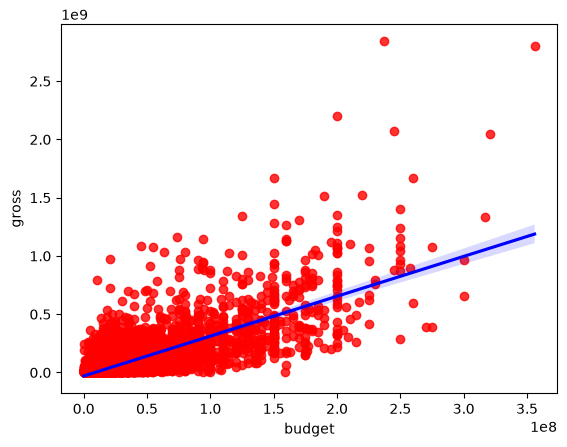

In [11]:
# plot the budget vs gross using seaborn

sns.regplot(x='budget',
            y='gross',
            data=df,
            scatter_kws={'color':'red'}, 
            line_kws={'color':'blue'})



In [12]:
df.corr(numeric_only=True, method='pearson')

,year,score,votes,budget,gross,runtime
year,1.000000,0.103928,0.227084,0.296131,0.262496,0.121383
score,0.103928,1.000000,0.412005,0.062853,0.187778,0.400949
votes,0.227084,0.412005,1.000000,0.460230,0.632343,0.309664
budget,0.296131,0.062853,0.460230,1.000000,0.746329,0.274028
gross,0.262496,0.187778,0.632343,0.746329,1.000000,0.244492
runtime,0.121383,0.400949,0.309664,0.274028,0.244492,1.000000


There is a  high correlation between the budget and the gross earnings

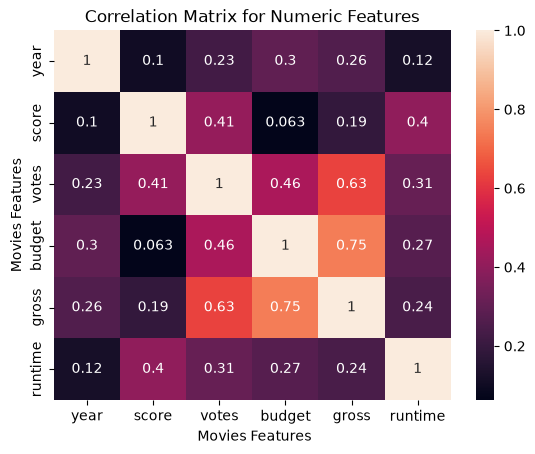

In [13]:
correlation_matrix = df.corr(numeric_only=True, method='pearson')
sns.heatmap(correlation_matrix, annot=True)
plt.title('Correlation Matrix for Numeric Features')
plt.xlabel(' Movies Features')
plt.ylabel('Movies Features')
plt.show()

In [14]:
df.dtypes

name         object
rating       object
genre        object
year          int64
released     object
score       float64
votes       float64
director     object
writer       object
star         object
country      object
budget        int64
gross         int64
company      object
runtime     float64
dtype: object

In [15]:
# Does the company influence the gross earnings of a movie?

df_numeric = df.copy()

for  col in df_numeric.columns:
    if df_numeric[col].dtype == 'object':
        df_numeric[col] = df_numeric[col].astype('category')
        df_numeric[col] = df_numeric[col].cat.codes

df_numeric.dtypes

name          int16
rating         int8
genre          int8
year          int64
released      int16
score       float64
votes       float64
director      int16
writer        int16
star          int16
country        int8
budget        int64
gross         int64
company       int16
runtime     float64
dtype: object

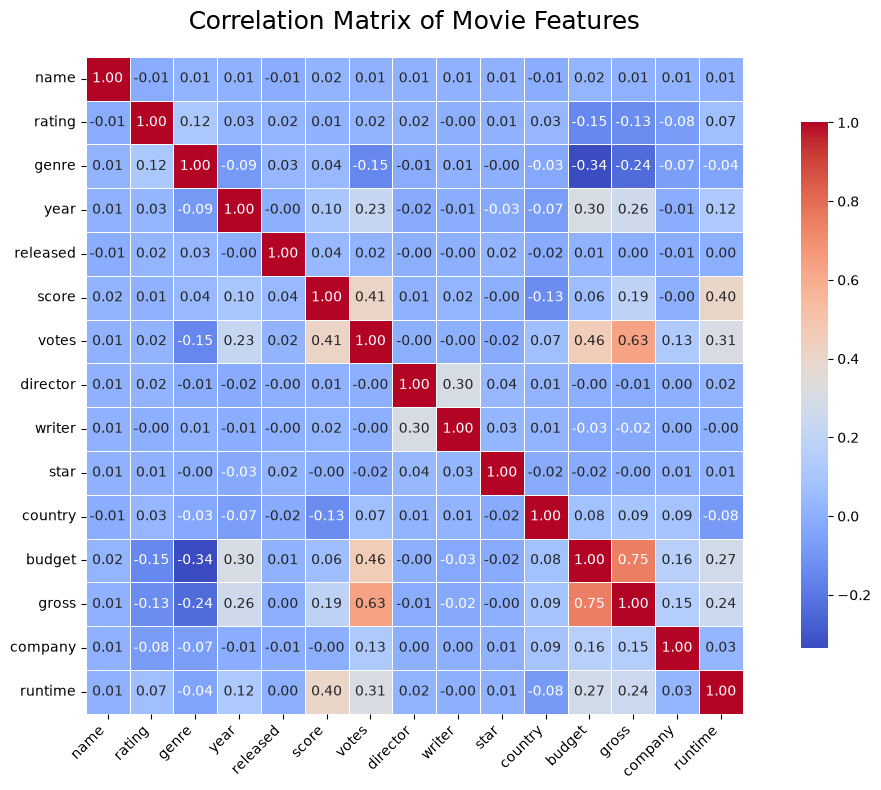

In [16]:

correlation_matrix = df_numeric.corr(numeric_only=True)
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    square=True,
    cbar_kws={"shrink": 0.8}
)

plt.title("Correlation Matrix of Movie Features", fontsize=18, pad=20)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [17]:
corr_matrix= df_numeric.corr()
corr_pairs = corr_matrix.unstack()
corr_pairs_sorted = corr_pairs.sort_values(ascending=False)
high_correlation = corr_pairs_sorted[(corr_pairs_sorted > 0.5) ]
high_correlation 

name      name        1.000000
rating    rating      1.000000
genre     genre       1.000000
released  released    1.000000
year      year        1.000000
score     score       1.000000
votes     votes       1.000000
writer    writer      1.000000
director  director    1.000000
budget    budget      1.000000
gross     gross       1.000000
runtime   runtime     1.000000
company   company     1.000000
star      star        1.000000
country   country     1.000000
budget    gross       0.746329
gross     budget      0.746329
          votes       0.632343
votes     gross       0.632343
dtype: float64

#### Conclusion:
 The budget and the votes have the highest correlation to gross earnings . The other varibales have less correlation with it 